<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session02_backpropagation_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۲: پس‌انتشار خطا و گرادیان کاهشی از صفر

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session02_backpropagation.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(0)
X, y = make_moons(n_samples=1000, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(P, y):
    return -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

به کلاس `Value` عملیات `tanh` و `exp` را اضافه کنید و با یک مثال، گرادیان را با مقدار تحلیلی مقایسه کنید.

</div>

In [2]:
class Value:
    def __init__(self, data, parents=()):
        self.data, self.grad = float(data), 0.0
        self._parents, self._backward = parents, lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,))
        def _backward():
            self.grad += (1 - t ** 2) * out.grad          # d tanh(x)/dx = 1 - tanh(x)^2
        out._backward = _backward
        return out

    def exp(self):
        e = math.exp(self.data)
        out = Value(e, (self,))
        def _backward():
            self.grad += e * out.grad                      # d exp(x)/dx = exp(x)
        out._backward = _backward
        return out

    def backward(self):
        order, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    build(p)
                order.append(v)
        build(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()


# f(x) = tanh(x) * exp(x)  ->  f'(x) = (1 - tanh^2 x) e^x + tanh(x) e^x
x = Value(0.7)
f = x.tanh() * x.exp()
f.backward()
analytic = (1 - math.tanh(0.7) ** 2) * math.exp(0.7) + math.tanh(0.7) * math.exp(0.7)
print(f'autograd: {x.grad:.6f} | analytic: {analytic:.6f}')

autograd: 2.495256 | analytic: 2.495256


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

چون `x` در دو مسیر (هم در `tanh` و هم در `exp`) استفاده شده، گرادیان دو مسیر با `+=` جمع می‌شود و نتیجه دقیقاً برابر مشتق تحلیلی (قاعدهٔ ضرب) است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

در `TwoLayerNet` تابع ReLU را با Tanh جایگزین کنید (مشتق: $1-\tanh^2$). گرادیان را با Gradient Checking بررسی کنید و سرعت همگرایی را مقایسه کنید.

</div>

gradient check (tanh):
  W1: relative error 4.6e-11
  b1: relative error 1.4e-10
  W2: relative error 3.0e-11
  b2: relative error 1.5e-11


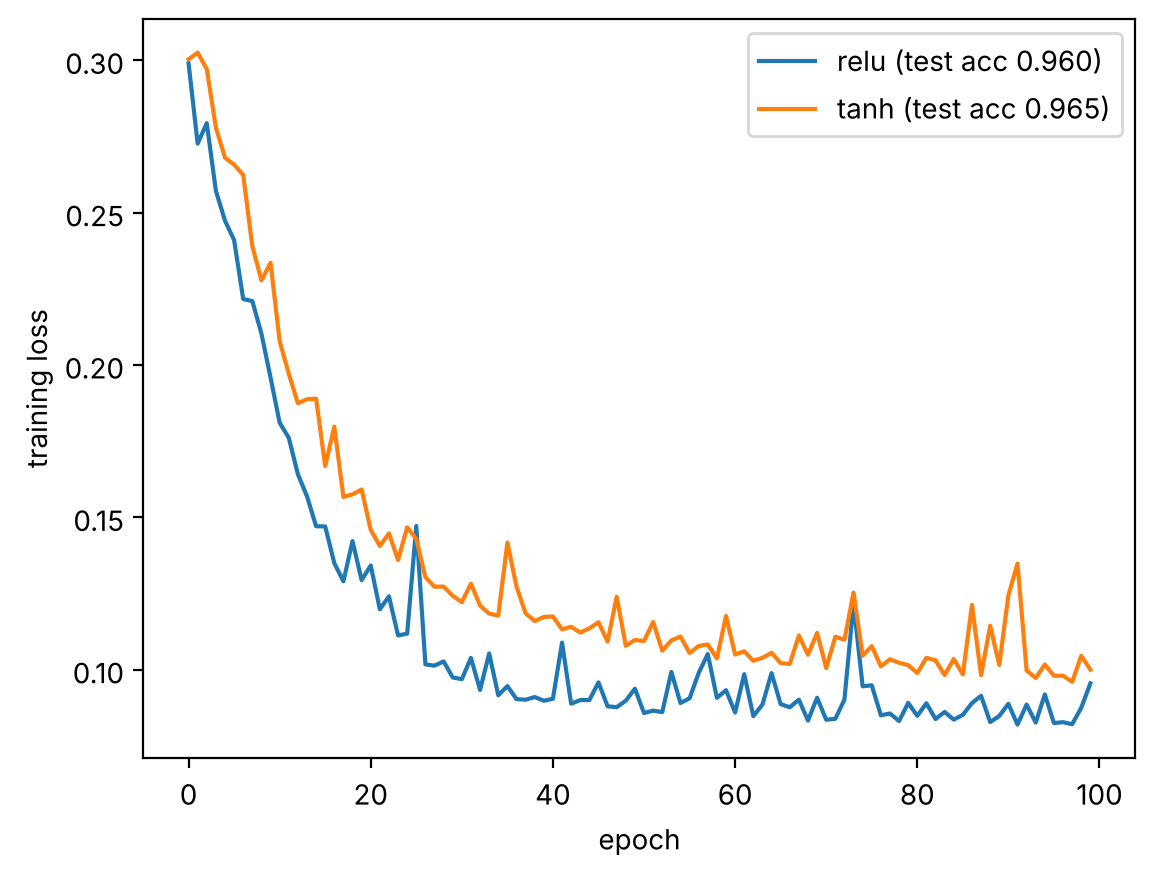

In [3]:
class TwoLayerNet:
    def __init__(self, n_in, n_hidden, n_out, activation='relu', seed=0):
        rng = np.random.default_rng(seed)
        gain = 2.0 if activation == 'relu' else 1.0
        self.activation = activation
        self.params = {'W1': rng.normal(0, np.sqrt(gain / n_in), (n_in, n_hidden)), 'b1': np.zeros(n_hidden),
                       'W2': rng.normal(0, np.sqrt(gain / n_hidden), (n_hidden, n_out)), 'b2': np.zeros(n_out)}

    def act(self, z):
        return np.maximum(0, z) if self.activation == 'relu' else np.tanh(z)

    def d_act(self, z):
        return (z > 0).astype(float) if self.activation == 'relu' else 1 - np.tanh(z) ** 2

    def forward(self, X):
        p = self.params
        Z1 = X @ p['W1'] + p['b1']
        H = self.act(Z1)
        P = softmax(H @ p['W2'] + p['b2'])
        self.cache = (X, Z1, H, P)
        return P

    def backward(self, y):
        X, Z1, H, P = self.cache
        dZ2 = (P - np.eye(P.shape[1])[y]) / len(y)
        dZ1 = (dZ2 @ self.params['W2'].T) * self.d_act(Z1)
        return {'W2': H.T @ dZ2, 'b2': dZ2.sum(0), 'W1': X.T @ dZ1, 'b1': dZ1.sum(0)}


def gradient_check(net, X, y, eps=1e-5):
    net.forward(X)
    analytic = net.backward(y)
    for name, theta in net.params.items():
        numeric = np.zeros_like(theta)
        for idx in np.ndindex(theta.shape):
            old = theta[idx]
            theta[idx] = old + eps; plus = cross_entropy(net.forward(X), y)
            theta[idx] = old - eps; minus = cross_entropy(net.forward(X), y)
            theta[idx] = old
            numeric[idx] = (plus - minus) / (2 * eps)
        err = np.abs(analytic[name] - numeric).max() / (np.abs(analytic[name]).max() + np.abs(numeric).max())
        print(f'  {name}: relative error {err:.1e}')


def train(net, epochs=100, lr=0.5, batch_size=64):
    losses = []
    for _ in range(epochs):
        perm = np.random.permutation(len(X_train))
        for s in range(0, len(X_train), batch_size):
            idx = perm[s:s + batch_size]
            net.forward(X_train[idx])
            grads = net.backward(y_train[idx])
            for k in net.params:
                net.params[k] -= lr * grads[k]
        losses.append(cross_entropy(net.forward(X_train), y_train))
    return losses


print('gradient check (tanh):')
gradient_check(TwoLayerNet(2, 5, 2, 'tanh', seed=1), X_train[:20], y_train[:20])

np.random.seed(0)
for activation in ('relu', 'tanh'):
    net = TwoLayerNet(2, 32, 2, activation)
    losses = train(net)
    acc = np.mean(net.forward(X_test).argmax(1) == y_test)
    plt.plot(losses, label=f'{activation} (test acc {acc:.3f})')
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

خطای نسبی Gradient Checking در حد $10^{-10}$ یا کمتر است؛ پس فرمول مشتق Tanh درست وارد شده است. در این شبکهٔ کم‌عمق هر دو تابع فعال‌سازی به دقت مشابهی می‌رسند. تفاوت سرعت همگرایی کوچک است و به نرخ یادگیری و مقداردهی اولیه بستگی دارد؛ مزیت واقعی ReLU در شبکه‌های **عمیق** دیده می‌شود، جایی که Tanh هم مثل Sigmoid اشباع می‌شود و گرادیان را محو می‌کند (بخش ۷ جلسه).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

حلقه آموزش را با `batch_size` برابر ۱، ۶۴ و کل داده اجرا کنید و نمودار Loss را مقایسه کنید. کدام سریع‌تر (بر حسب زمان واقعی) همگرا می‌شود؟

</div>

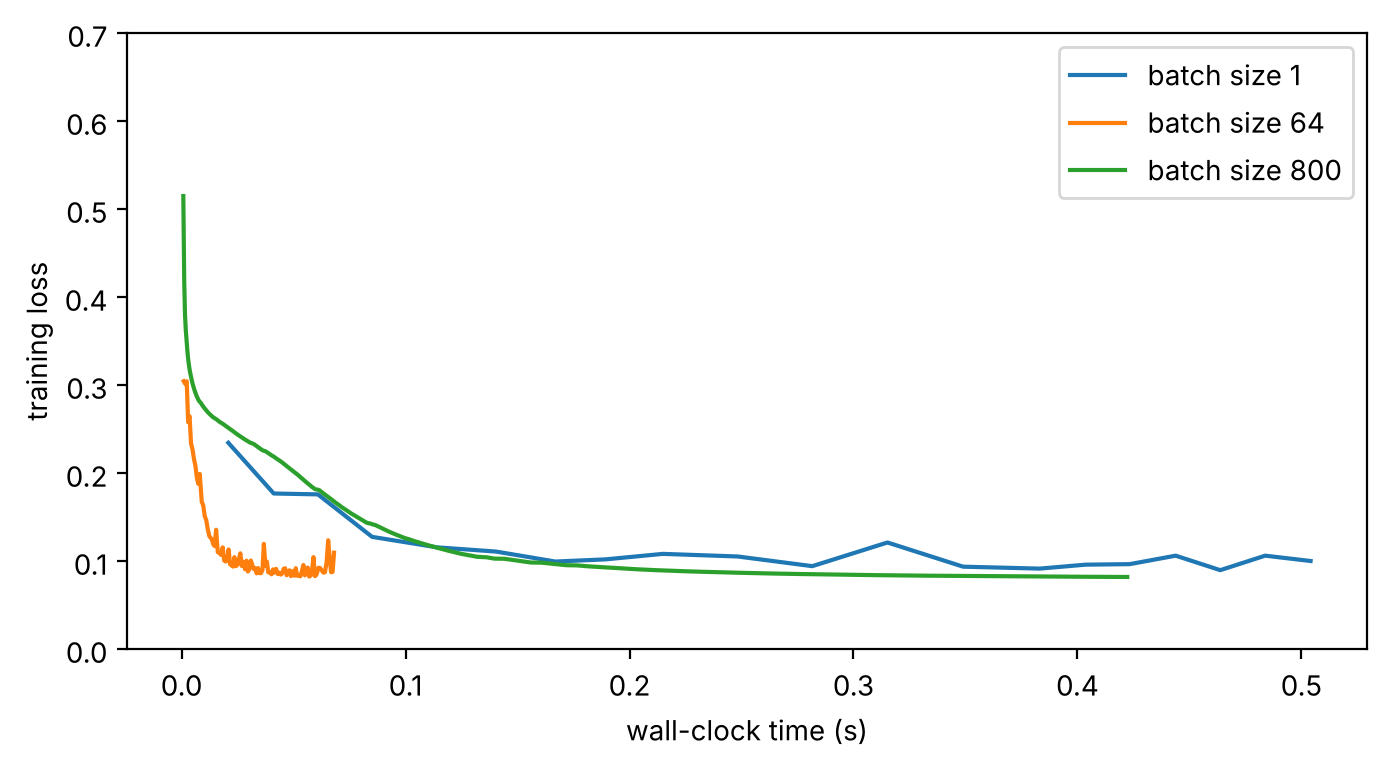

In [4]:
np.random.seed(0)
plt.figure(figsize=(8, 4))
for batch_size, epochs in [(1, 20), (64, 100), (len(X_train), 1000)]:
    net = TwoLayerNet(2, 32, 2, 'relu')
    lr = 0.05 if batch_size == 1 else 0.5
    start = time.perf_counter()
    times, losses = [], []
    for _ in range(epochs):
        losses += train(net, epochs=1, lr=lr, batch_size=batch_size)
        times.append(time.perf_counter() - start)
    plt.plot(times, losses, label=f'batch size {batch_size}')
plt.xlabel('wall-clock time (s)'); plt.ylabel('training loss'); plt.ylim(0, 0.7); plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نمودار بر حسب **زمان واقعی** رسم شده است:

- با `batch_size=1` هر به‌روزرسانی بسیار ارزان ولی پرنویز است و پیاده‌سازی پایتونی برای هر نمونه یک بار حلقه می‌زند؛ پس در زمان واقعی کند است و Loss نوسان دارد (برای پایداری، نرخ یادگیری را کوچک کردیم).
- با کل داده (Batch GD) هر قدم دقیق ولی پرهزینه است و در هر Epoch فقط یک به‌روزرسانی انجام می‌شود.
- Mini-batch معمولاً بهترین مصالحه است: محاسبات برداری NumPy (و روی GPU، موازی‌سازی) را به‌خوبی به کار می‌گیرد و در هر Epoch چندین به‌روزرسانی انجام می‌دهد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

یک لایه پنهان دوم به شبکه اضافه کنید (`TwoLayerNet` را به `ThreeLayerNet` تبدیل کنید) و فرمول‌های Backward را برای آن بنویسید.

</div>

In [5]:
class ThreeLayerNet:
    def __init__(self, n_in, h1, h2, n_out, seed=0):
        rng = np.random.default_rng(seed)
        self.params = {'W1': rng.normal(0, np.sqrt(2 / n_in), (n_in, h1)), 'b1': np.zeros(h1),
                       'W2': rng.normal(0, np.sqrt(2 / h1), (h1, h2)), 'b2': np.zeros(h2),
                       'W3': rng.normal(0, np.sqrt(2 / h2), (h2, n_out)), 'b3': np.zeros(n_out)}

    def forward(self, X):
        p = self.params
        Z1 = X @ p['W1'] + p['b1']; H1 = np.maximum(0, Z1)
        Z2 = H1 @ p['W2'] + p['b2']; H2 = np.maximum(0, Z2)
        P = softmax(H2 @ p['W3'] + p['b3'])
        self.cache = (X, Z1, H1, Z2, H2, P)
        return P

    def backward(self, y):
        X, Z1, H1, Z2, H2, P = self.cache
        p = self.params
        dZ3 = (P - np.eye(P.shape[1])[y]) / len(y)
        dZ2 = (dZ3 @ p['W3'].T) * (Z2 > 0)
        dZ1 = (dZ2 @ p['W2'].T) * (Z1 > 0)
        return {'W3': H2.T @ dZ3, 'b3': dZ3.sum(0), 'W2': H1.T @ dZ2, 'b2': dZ2.sum(0),
                'W1': X.T @ dZ1, 'b1': dZ1.sum(0)}


print('gradient check (three layers):')
gradient_check(ThreeLayerNet(2, 6, 5, 2, seed=1), X_train[:20], y_train[:20])
np.random.seed(0)
net = ThreeLayerNet(2, 32, 32, 2)
train(net, epochs=100, lr=0.3)
print('test accuracy:', np.mean(net.forward(X_test).argmax(1) == y_test))

gradient check (three layers):
  W1: relative error 1.4e-10
  b1: relative error 1.7e-10
  W2: relative error 7.7e-11
  b2: relative error 8.4e-11
  W3: relative error 8.9e-12
  b3: relative error 3.6e-11
test accuracy: 0.95


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فرمول‌ها همان الگوی دولایه را یک لایه بیشتر تکرار می‌کنند:

$$\frac{\partial \mathcal{L}}{\partial Z_3} = \frac{1}{N}(P - Y),\qquad \frac{\partial \mathcal{L}}{\partial Z_2} = \left(\frac{\partial \mathcal{L}}{\partial Z_3} W_3^\top\right)\odot\mathbb{1}[Z_2 > 0],\qquad \frac{\partial \mathcal{L}}{\partial Z_1} = \left(\frac{\partial \mathcal{L}}{\partial Z_2} W_2^\top\right)\odot\mathbb{1}[Z_1 > 0]$$

و برای هر لایه $\frac{\partial \mathcal{L}}{\partial W_l} = H_{l-1}^\top \frac{\partial \mathcal{L}}{\partial Z_l}$ و $\frac{\partial \mathcal{L}}{\partial \mathbf{b}_l} = \sum_i \left(\frac{\partial \mathcal{L}}{\partial Z_l}\right)_i$. هر لایهٔ اضافه فقط یک ضرب ماتریسی با ترانهادهٔ وزن و یک ضرب در مشتق تابع فعال‌سازی اضافه می‌کند؛ این الگوی تکراری همان چیزی است که autograd در PyTorch خودکار انجام می‌دهد.

</div>